# DDoS Detection

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, f1_score

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [3]:
ddos_files = {
    "LDAP_train": "./data_train/LDAP-training.parquet",
    "MSSQL_train": "./data_train/MSSQL-training.parquet",
    "NetBIOS_train": "./data_train/NetBIOS-training.parquet",
    "Portmap_train": "./data_train/Portmap-training.parquet",
    "Syn_train": "./data_train/Syn-training.parquet",
    "UDPLag_train": "./data_train/UDPLag-training.parquet",
    "UDP_train": "./data_train/UDP-training.parquet",

    "DNS_test": "./data_test/DNS-testing.parquet",
    "LDAP_test": "./data_test/LDAP-testing.parquet",
    "MSSQL_test": "./data_test/MSSQL-testing.parquet",
    "NetBIOS_test": "./data_test/NetBIOS-testing.parquet",
    "NTP_test": "./data_test/NTP-testing.parquet",
    "SNMP_test": "./data_test/SNMP-testing.parquet",
    "Syn_test": "./data_test/Syn-testing.parquet",
    "TFTP_test": "./data_test/TFTP-testing.parquet",
    "UDPLag_test": "./data_test/UDPLag-testing.parquet",
    "UDP_test": "./data_test/UDP-testing.parquet",
}

class_names = ["BENIGN", "SYN", "UDP", "DrDoS"]

In [4]:
for name, path in ddos_files.items():
    df = pq.read_table(path).to_pandas()
    print(df["Label"].unique())

['NetBIOS', 'LDAP', 'Benign']
Categories (3, str): ['Benign', 'LDAP', 'NetBIOS']
['MSSQL', 'LDAP', 'Benign']
Categories (3, str): ['Benign', 'LDAP', 'MSSQL']
['NetBIOS', 'Benign']
Categories (2, str): ['Benign', 'NetBIOS']
['Portmap', 'Benign']
Categories (2, str): ['Benign', 'Portmap']
['Syn', 'Benign']
Categories (2, str): ['Benign', 'Syn']
['UDP', 'Syn', 'UDPLag', 'Benign']
Categories (4, str): ['Benign', 'Syn', 'UDP', 'UDPLag']
['UDP', 'MSSQL', 'Benign']
Categories (3, str): ['Benign', 'MSSQL', 'UDP']
['DrDoS_DNS', 'Benign']
Categories (2, str): ['Benign', 'DrDoS_DNS']
['DrDoS_LDAP', 'Benign']
Categories (2, str): ['Benign', 'DrDoS_LDAP']
['DrDoS_MSSQL', 'Benign']
Categories (2, str): ['Benign', 'DrDoS_MSSQL']
['DrDoS_NetBIOS', 'Benign']
Categories (2, str): ['Benign', 'DrDoS_NetBIOS']
['DrDoS_NTP', 'Benign']
Categories (2, str): ['Benign', 'DrDoS_NTP']
['DrDoS_SNMP', 'Benign']
Categories (2, str): ['Benign', 'DrDoS_SNMP']
['Syn', 'Benign']
Categories (2, str): ['Benign', 'Syn']
['

In [5]:
labels = {
    "Benign": 0, # X

    "Syn": 1, # X
  
    "UDP": 2, # X
    "UDP-lag": 2, # X
    "UDPLag": 2, # X
    "DrDoS_UDP": 2, # X
    "TFTP": 2, # X

    "LDAP": 3, # X
    "DrDoS_LDAP": 3, # X
    "MSSQL": 3, # X
    "DrDoS_MSSQL": 3, # X
    "NetBIOS": 3, # X
    "DrDoS_NetBIOS": 3, # X
    "Portmap": 3, # X
    "DrDoS_DNS": 3, # X
    "DrDoS_NTP": 3, # X
    "DrDoS_SNMP": 3, # X
    "WebDDoS": 3, # X
}

In [6]:
def load_files(name, path):
    df = pq.read_table(path).to_pandas()
    df.columns = df.columns.astype(str).str.strip()
    df["source_file"] = name
    return df

dfs = []
for name, path in ddos_files.items():
    dfs.append(load_files(name, path))

data = pd.concat(dfs, ignore_index=True)
data.head()

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,17,49,2,0,458.0,0.0,229.0,229.0,229.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NetBIOS,LDAP_train
1,17,1,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,LDAP,LDAP_train
2,17,1,2,0,458.0,0.0,229.0,229.0,229.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NetBIOS,LDAP_train
3,17,1,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,LDAP,LDAP_train
4,17,1,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,LDAP,LDAP_train


In [7]:
print("Labels and their number in dataset")
print(data["Label"].value_counts(dropna=False).head(30))

Labels and their number in dataset
Label
DrDoS_NTP        121368
TFTP              98917
Benign            97831
Syn               49373
UDP               18090
DrDoS_UDP         10420
UDP-lag            8872
MSSQL              8523
DrDoS_MSSQL        6212
DrDoS_DNS          3669
DrDoS_SNMP         2717
LDAP               1906
DrDoS_LDAP         1440
Portmap             685
NetBIOS             644
DrDoS_NetBIOS       598
UDPLag               55
WebDDoS              51
Name: count, dtype: int64


In [8]:
data.shape

(431371, 79)

In [9]:
data["Label"] = data["Label"].map(labels)

data = data.dropna(subset=["Label"]).copy()
data["Label"] = data["Label"].astype(int)

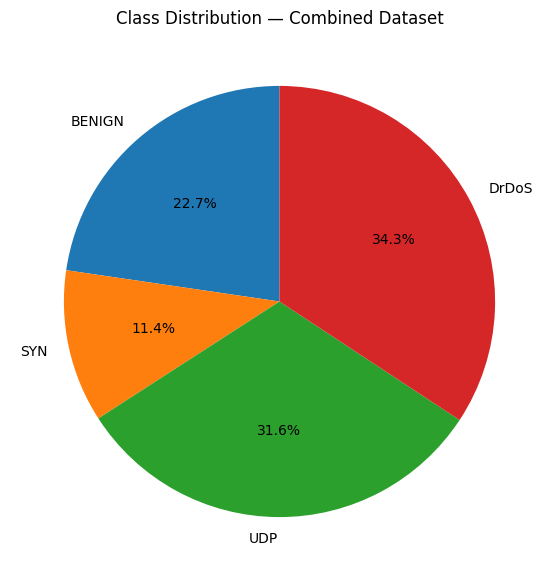

In [10]:
counts = data["Label"].value_counts().sort_index()
labels = [class_names[i] for i in counts.index]

plt.figure(figsize=(7, 7))
plt.pie(counts.values, labels=labels, autopct="%1.1f%%", startangle=90)
plt.title("Class Distribution — Combined Dataset")
plt.show()

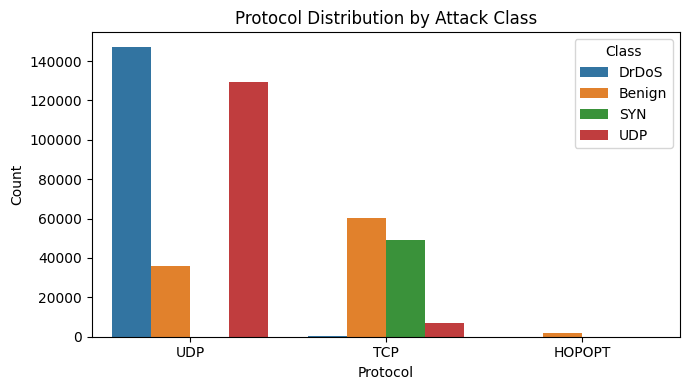

In [11]:
import seaborn as sns

label_names = {0: "Benign", 1: "SYN", 2: "UDP", 3: "DrDoS"}
protocol_names = {6: 'TCP', 17: 'UDP', 0: 'HOPOPT'}

ddos_plot = data.copy()
ddos_plot['Protocol_name'] = ddos_plot['Protocol'].map(protocol_names)
ddos_plot['Label_name'] = ddos_plot['Label'].map(label_names)

plt.figure(figsize=(7, 4))
sns.countplot(data=ddos_plot, x='Protocol_name', hue='Label_name')
plt.title('Protocol Distribution by Attack Class')
plt.xlabel('Protocol')
plt.ylabel('Count')
plt.legend(title='Class')
plt.tight_layout()
plt.show()

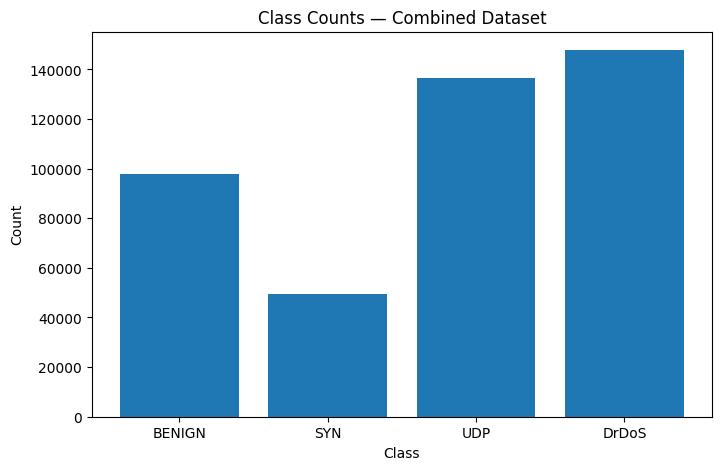

In [12]:
plt.figure(figsize=(8, 5))
plt.bar(labels, counts.values)
plt.title("Class Counts — Combined Dataset")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [13]:
constant_columns = data.columns[data.nunique() <= 1]
print(f"Constant columns: {constant_columns.tolist()}")

data.drop(columns=constant_columns, inplace=True)
print(f"Shape after dropping constant columns: {data.shape}")

Constant columns: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'FIN Flag Count', 'PSH Flag Count', 'ECE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Shape after dropping constant columns: (431371, 67)


In [14]:
ddos_data_cp = data.select_dtypes(include='number').copy()
correlation_matrix = ddos_data_cp.corr()

correlated_features = []
for f1 in correlation_matrix.columns:
    for f2 in correlation_matrix.columns:
        if abs(correlation_matrix.loc[f1, f2]) > 0.9 and f1 != f2:
            correlated_features.append((f1, f2))

printed_pairs = set()
for f1, f2 in correlated_features:
    if (f2, f1) not in printed_pairs:
        print(f"{f1} and {f2} are highly correlated: {correlation_matrix.loc[f1, f2]:.3f}")
        printed_pairs.add((f1, f2))

Flow Duration and Fwd IAT Total are highly correlated: 0.999
Total Fwd Packets and Subflow Fwd Packets are highly correlated: 1.000
Total Backward Packets and Bwd Packets Length Total are highly correlated: 0.974
Total Backward Packets and Subflow Bwd Packets are highly correlated: 1.000
Total Backward Packets and Subflow Bwd Bytes are highly correlated: 0.974
Fwd Packets Length Total and Subflow Fwd Bytes are highly correlated: 1.000
Bwd Packets Length Total and Subflow Bwd Packets are highly correlated: 0.974
Bwd Packets Length Total and Subflow Bwd Bytes are highly correlated: 1.000
Fwd Packet Length Min and Fwd Packet Length Mean are highly correlated: 0.957
Fwd Packet Length Min and Packet Length Min are highly correlated: 0.997
Fwd Packet Length Min and Packet Length Mean are highly correlated: 0.924
Fwd Packet Length Min and Avg Packet Size are highly correlated: 0.934
Fwd Packet Length Min and Avg Fwd Segment Size are highly correlated: 0.957
Fwd Packet Length Mean and Packet L

In [15]:
related_features_corr = {
    'G1': ['Flow Duration', 'Fwd IAT Total'],
    'G2': ['Total Fwd Packets', 'Subflow Fwd Packets'],
    'G3': ['Total Backward Packets', 'Bwd Packets Length Total', 'Subflow Bwd Packets', 'Subflow Bwd Bytes'],
    'G4': ['Fwd Packets Length Total', 'Subflow Fwd Bytes'],
    'G5': ['Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Packet Length Min', 'Packet Length Mean', 'Avg Packet Size', 'Avg Fwd Segment Size'],
    'G6': ['Bwd Packet Length Max', 'Bwd Packet Length Std', 'Packet Length Std'],
    'G7': ['Bwd Packet Length Mean', 'Avg Bwd Segment Size'],
    'G8': ['Flow Packets/s', 'Fwd Packets/s'],
    'G9': ['Flow IAT Mean', 'Flow IAT Std', 'Fwd IAT Mean', 'Fwd IAT Std', 'Flow IAT Max', 'Fwd IAT Max', 'Idle Mean', 'Idle Max', 'Idle Min'],
    'G10': ['Flow IAT Min', 'Fwd IAT Min'],
    'G11': ['Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max'],
    'G12': ['Fwd PSH Flags', 'RST Flag Count'],
    'G13': ['Active Mean', 'Active Min']
}

columns_to_drop = []

for group_name, cols in related_features_corr.items():
    available_cols = [c for c in cols if c in data.columns]
    correlations = data[available_cols + ['Label']].corr()['Label'].drop('Label').abs()
    correlations_sorted = correlations.sort_values(ascending=False)
    best_feature = correlations_sorted.index[0]
    features_to_drop = correlations_sorted.index[1:].tolist()
    columns_to_drop.extend(features_to_drop)
    
data.drop(columns=columns_to_drop, inplace=True, errors='ignore')
print(f"Shape dupa drop: {data.shape}")

Shape dupa drop: (431371, 39)


In [16]:
zero_var_cols = [col for col in data.select_dtypes(include='number').columns if data[col].std() == 0]
data.drop(columns=zero_var_cols, inplace=True, errors='ignore')

In [17]:
data.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Fwd Packets Length Total',
       'Fwd Packet Length Max', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Min',
       'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s',
       'Flow IAT Max', 'Flow IAT Min', 'Bwd IAT Total', 'Bwd IAT Max',
       'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length',
       'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
       'Packet Length Max', 'Packet Length Variance', 'SYN Flag Count',
       'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'Down/Up Ratio',
       'Init Fwd Win Bytes', 'Init Bwd Win Bytes', 'Fwd Act Data Packets',
       'Fwd Seg Size Min', 'Active Mean', 'Active Std', 'Active Max',
       'Idle Std', 'Label', 'source_file'],
      dtype='str')

In [18]:
print(len(data.columns))
feature_columns = data.columns.to_list()
print(feature_columns)

39
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow IAT Max', 'Flow IAT Min', 'Bwd IAT Total', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Max', 'Packet Length Variance', 'SYN Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'Down/Up Ratio', 'Init Fwd Win Bytes', 'Init Bwd Win Bytes', 'Fwd Act Data Packets', 'Fwd Seg Size Min', 'Active Mean', 'Active Std', 'Active Max', 'Idle Std', 'Label', 'source_file']


In [19]:
feature_columns = [col for col in data.columns if col not in ['Label', 'source_file']]
X = data[feature_columns].copy()
y = data["Label"].copy()
sources = data["source_file"].copy()

X_train, X_temp, y_train, y_temp, src_train, src_temp = train_test_split(X, y, sources, test_size=0.30, random_state=RANDOM_STATE, stratify=y)
X_val, X_test, y_val, y_test, src_val, src_test = train_test_split(X_temp, y_temp, src_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (301959, 37)
Validation: (64706, 37)
Test: (64706, 37)


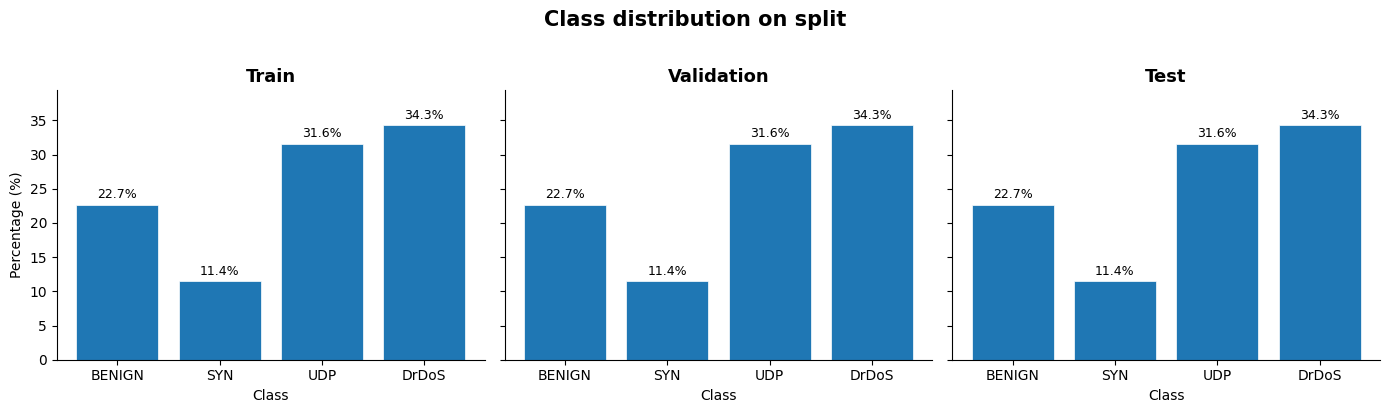

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

splits = {"Train": y_train, "Validation": y_val, "Test": y_test}

for ax, (split_name, y_split) in zip(axes, splits.items()):
    counts = y_split.value_counts(normalize=True).sort_index() * 100
    class_labels = [class_names[i] for i in counts.index]

    bars = ax.bar(class_labels, counts.values, edgecolor='white', linewidth=0.5)

    for bar, val in zip(bars, counts.values):
        x = bar.get_x() + bar.get_width() / 2
        y = bar.get_height() + 0.5
        ax.text(x, y, f'{val:.1f}%', ha='center', va='bottom', fontsize=9)

    ax.set_title(split_name, fontsize=13, fontweight='bold')
    ax.set_xlabel('Class')
    ax.set_ylim(0, counts.max() * 1.15)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[0].set_ylabel('Percentage (%)')

fig.suptitle('Class distribution on split', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [21]:
model_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0
)
model_rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [22]:
val_pred = model_rf.predict(X_val)

print("Accuracy:", accuracy_score(y_val, val_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_val, val_pred))
print("Macro F1:", f1_score(y_val, val_pred, average="macro"))
print("Weighted F1:", f1_score(y_val, val_pred, average="weighted"))

print("\nClassification report — Validation")
print(classification_report(y_val, val_pred, labels=[0, 1, 2, 3], target_names=class_names, zero_division=0))

Accuracy: 0.9949618273421321
Balanced accuracy: 0.9947354351758011
Macro F1: 0.9947992524970125
Weighted F1: 0.9949607493278798

Classification report — Validation
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     14675
         SYN       0.99      0.99      0.99      7406
         UDP       0.99      0.99      0.99     20453
       DrDoS       0.99      1.00      0.99     22172

    accuracy                           0.99     64706
   macro avg       0.99      0.99      0.99     64706
weighted avg       0.99      0.99      0.99     64706



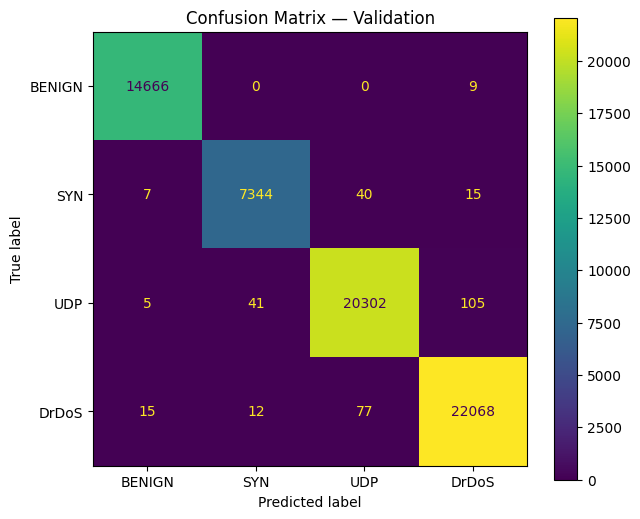

In [23]:
cm_val = confusion_matrix(y_val, val_pred, labels=[0, 1, 2, 3])

disp = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=class_names)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, values_format="d")
plt.title("Confusion Matrix — Validation")
plt.show()

In [24]:
test_pred = model_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, test_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_test, test_pred))
print("Macro F1:", f1_score(y_test, test_pred, average="macro"))
print("Weighted F1:", f1_score(y_test, test_pred, average="weighted"))

print("\nClassification report — Test")
print(classification_report(y_test, test_pred, labels=[0, 1, 2, 3], target_names=class_names, zero_division=0))

Accuracy: 0.9943436466479152
Balanced accuracy: 0.9944170688343706
Macro F1: 0.9941270040026166
Weighted F1: 0.9943429398393373

Classification report — Test
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     14675
         SYN       0.99      0.99      0.99      7406
         UDP       0.99      0.99      0.99     20453
       DrDoS       0.99      0.99      0.99     22172

    accuracy                           0.99     64706
   macro avg       0.99      0.99      0.99     64706
weighted avg       0.99      0.99      0.99     64706



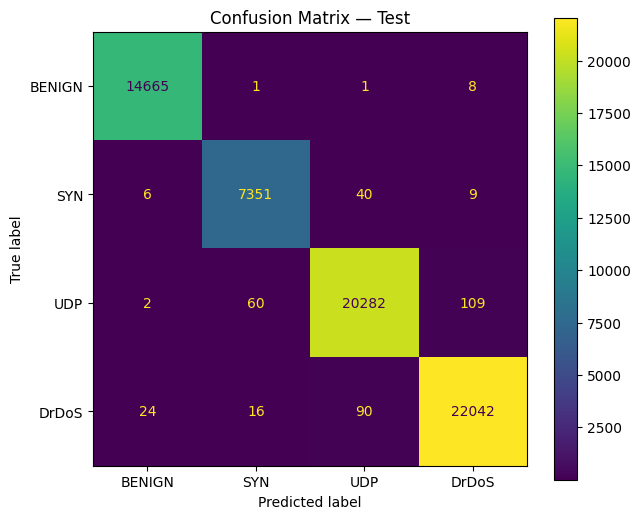

In [25]:
cm_test = confusion_matrix(y_test, test_pred, labels=[0, 1, 2, 3])

disp = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=class_names)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, values_format="d")
plt.title("Confusion Matrix — Test")
plt.show()

In [26]:
test_results = pd.DataFrame({"true": y_test.values, "pred": test_pred, "source_file": src_test.values})

for src in sorted(test_results["source_file"].unique()):
    part = test_results[test_results["source_file"] == src]
    print("\n" + "=" * 80)
    print(f"Source file: {src}")
    print("Samples:", len(part))
    print(classification_report(part["true"], part["pred"], labels=[0, 1, 2, 3], target_names=class_names, zero_division=0))


Source file: DNS_test
Samples: 995
              precision    recall  f1-score   support

      BENIGN       0.99      1.00      0.99       447
         SYN       0.00      0.00      0.00         0
         UDP       0.00      0.00      0.00         0
       DrDoS       1.00      0.96      0.98       548

    accuracy                           0.98       995
   macro avg       0.50      0.49      0.49       995
weighted avg       0.99      0.98      0.99       995


Source file: LDAP_test
Samples: 453
              precision    recall  f1-score   support

      BENIGN       1.00      0.99      0.99       228
         SYN       0.00      0.00      0.00         0
         UDP       0.00      0.00      0.00         0
       DrDoS       1.00      0.99      0.99       225

    accuracy                           0.99       453
   macro avg       0.50      0.50      0.50       453
weighted avg       1.00      0.99      0.99       453


Source file: LDAP_train
Samples: 1016
              prec

In [27]:
importances = pd.DataFrame({"feature": feature_columns, "importance": model_rf.feature_importances_}).sort_values("importance", ascending=False)

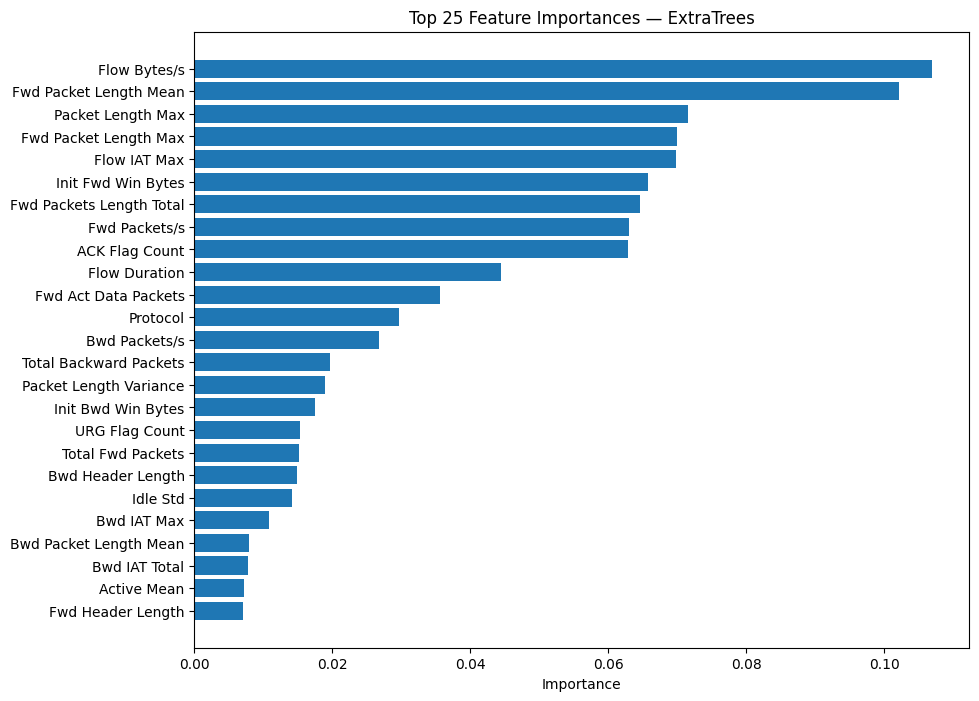

In [28]:
plt.figure(figsize=(10, 8))
top = importances.head(25).sort_values("importance")
plt.barh(top["feature"], top["importance"])
plt.title("Top 25 Feature Importances — ExtraTrees")
plt.xlabel("Importance")
plt.show()

In [29]:
OUTPUT_DIR = "ddos_model"
os.makedirs(OUTPUT_DIR, exist_ok=True)

joblib.dump(model_rf, os.path.join(OUTPUT_DIR, "ddos_model.joblib"))

metadata = {
    "model_type": "RandomForestClassifier",
    "n_estimators": 300,
    "class_names": ["BENIGN", "SYN", "UDP", "DrDoS"],
    "label_mapping": {"0": "BENIGN", "1": "SYN", "2": "UDP", "3": "DrDoS"},
    "feature_columns": feature_columns,
}

with open(os.path.join(OUTPUT_DIR, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)